# 08 — Deep dive: chamber control, opposition within members, topics, turnover

**Preliminary — for the analysis chapter's deep dive, after notebook 07 (A6).**

The same speeches as notebook 07: the `d100k` run (`20261018T122536Z`; S19, P8), 99,996
floor speeches, 1,923 per Congress × party × chamber, scored for ideology (−1 liberal …
+1 conservative) and tone (0 neutral … 1 hostile) by DeepSeek-V4.1-Flash-1017 alone, with
speech type and topic from label run `20261017T182223Z` (L1–L8, not yet hand-checked, L4).
`df` is substantive speech (A3), as in 07.

Five analyses, each new beside notebook 07:

1. **Chamber control** — who held each chamber, and the four constellations of White House
   and chamber majority.
2. **Opposition within members** — 07's opposition effect (model A), with the chamber
   minority (B), and with member fixed effects (C).
3. **Topic blocks in one model** — the party gap per block and Congress from one
   regression, with tests across blocks.
4. **Agenda against positions** — how much of the change in the policy-debate gap comes
   from moving within blocks, how much from the debate shifting between them.
5. **Replacement against adaptation** — how much of each party's move comes from members
   who stayed, how much from who entered and who left.

Logic in `code/src/deep_dive.py`, figures in `code/src/deep_dive_plots.py` (tested in
`code/tests/test_deep_dive.py`). Figures `results/plots/deepdive_*.png`, tables
`results/metrics/deepdive_*_20261018T122536Z.csv`. House and Senate are never pooled;
every interval is clustered by member.

In [3]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(ROOT / "code"))

import matplotlib.pyplot as plt
import pandas as pd

from src.analysis import (
    attach_labels,
    cell_means,
    load_scored_run,
    party_gap,
    substantive,
    toward_party,
)
from src.config import METRICS_DIR, SCORES_DIR, TOPIC_BLOCKS
from src.deep_dive import (
    CONSTELLATIONS,
    DECOMPOSITION_COMPARISONS,
    DEEP_DIVE_BOOTSTRAP,
    TOPIC_MIN_CELL,
    TOPIC_TEST_CONGRESSES,
    TURNOVER_WINDOWS,
    add_chamber_control,
    bootstrap_gap_decomposition,
    bootstrap_turnover,
    chamber_membership,
    check_reproduces,
    control_cells,
    fit_topic_model,
    identifying_members,
    majority_table,
    opposition_models,
    robustness_samples,
    specter_miscoded,
    stayers_without_speeches,
    topic_cell_sizes,
    topic_gap_tests,
    topic_gaps,
    turnover_decomposition,
    turnover_robustness,
)
from src.deep_dive_plots import (
    plot_gap_decomposition,
    plot_opposition_models,
    plot_positions_with_control,
    plot_turnover,
)
from src.plots import plot_gap_by_group, plot_group_means, save_figure
from src.runs import run_models

%matplotlib inline
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 60)

RUN = "20261018T122536Z"        # d100k: 99,996 speeches, DeepSeek alone (S19)
LABEL_RUN = "20261017T182223Z"  # speech type and topic (L1-L8)

everything = attach_labels(load_scored_run(RUN), LABEL_RUN).dropna(subset=["ideology"])
df = substantive(everything)    # A3: procedural and ceremonial left out by label
df = add_chamber_control(df).assign(
    extremity=lambda f: toward_party(f),            # R as scored, D sign-flipped
    opposition=lambda f: f["in_opposition"].astype(float),
)
policy = df[df["speech_type"] == "policy_debate"]  # only policy debates carry a topic
(MODEL,) = run_models(SCORES_DIR, RUN)
print(f"Model {MODEL}: {len(everything):,} scored speeches; {len(df):,} substantive; "
      f"{len(policy):,} policy debates")

Model deepseek-flash: 99,993 scored speeches; 71,121 substantive; 67,150 policy debates


In [4]:
def with_ci(table, value="mean", digits=2):
    """'0.46 [0.35, 0.57]' -- a value with its 95% interval."""
    return table.apply(
        lambda r: f"{r[value]:+.{digits}f} [{r['ci_low']:+.{digits}f}, {r['ci_high']:+.{digits}f}]",
        axis=1,
    )


def model_table(models, terms=("opposition", "chamber_minority")):
    """Models side by side: coefficient [95% interval] per chamber, party, model and term."""
    shown = models[models["term"].isin(terms)].assign(coef_ci=lambda f: with_ci(f, "coef", 3))
    return shown.pivot(index=["chamber", "party"], columns=["term", "model"], values="coef_ci")

# Part I — Who holds power

## 1. Chamber control

Notebook 07 measures power by the White House only (`in_opposition`). Here each speech also
gets the majority of the speaker's own chamber **on the day of the speech**: the Senate
changed hands within the 107th Congress (Gore until 20 January 2001, Cheney, then the
Democrats from Jeffords's switch on 6 June 2001) and the 117th (Republicans until
20 January 2021). Sources and the table: `deep_dive.HOUSE_MAJORITY`, `SENATE_MAJORITY`,
`SENATE_MAJORITY_CHANGES`.

- `chamber_minority` — the speaker's party is not the majority of their chamber.

In [5]:
control = majority_table()
control

,congress_number,senate_from,house_majority,senate_majority
0,107,2001-01-03,R,D
1,107,2001-01-20,R,R
2,107,2001-06-06,R,D
3,108,None,R,R
4,109,None,R,R
5,110,None,D,D
6,111,None,D,D
7,112,None,R,D
8,113,None,R,D
9,114,None,R,R


In [6]:
print("Speeches per constellation (substantive):")
df.groupby(["chamber", "party", "in_opposition", "chamber_minority"]).size().unstack(["in_opposition", "chamber_minority"])

Speeches per constellation (substantive):


in_opposition    False       True       
chamber_minority     0     1     0     1
chamber party                           
H       D         2944  6229  2994  7762
        R         6747  2803  5803  2960
S       D         5574  1458  2076  7684
        R         5727  2413  1035  6912

**Positions and tone per Congress, with chamber control.** The strip along the top of each
panel shows which party held that chamber; presidential terms are shaded behind the data.

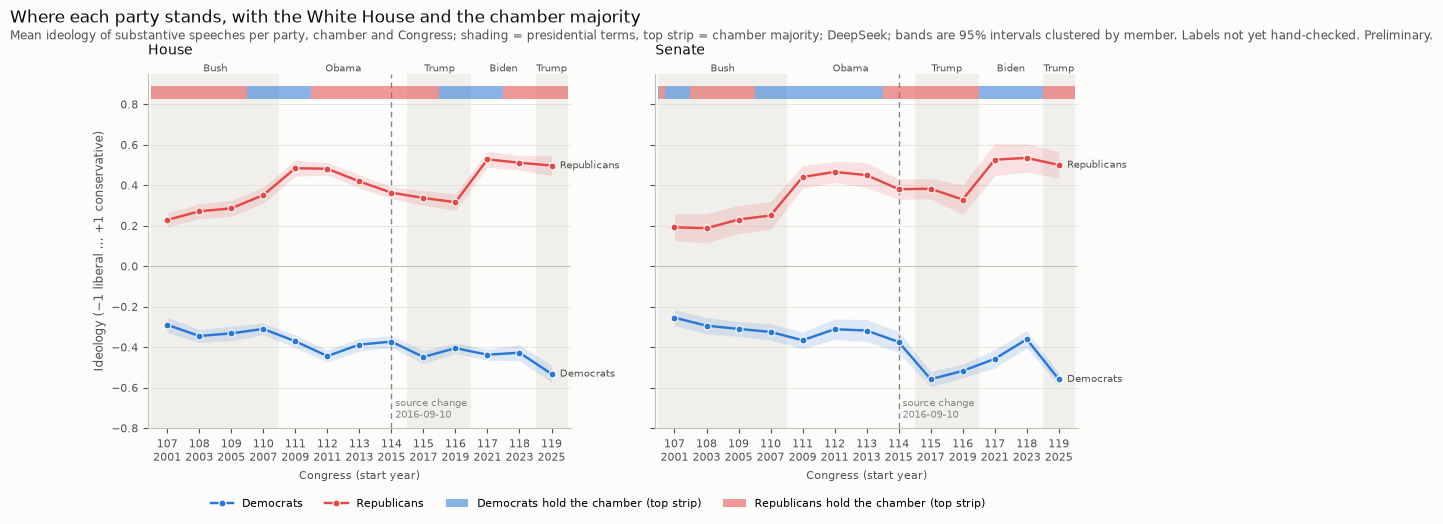

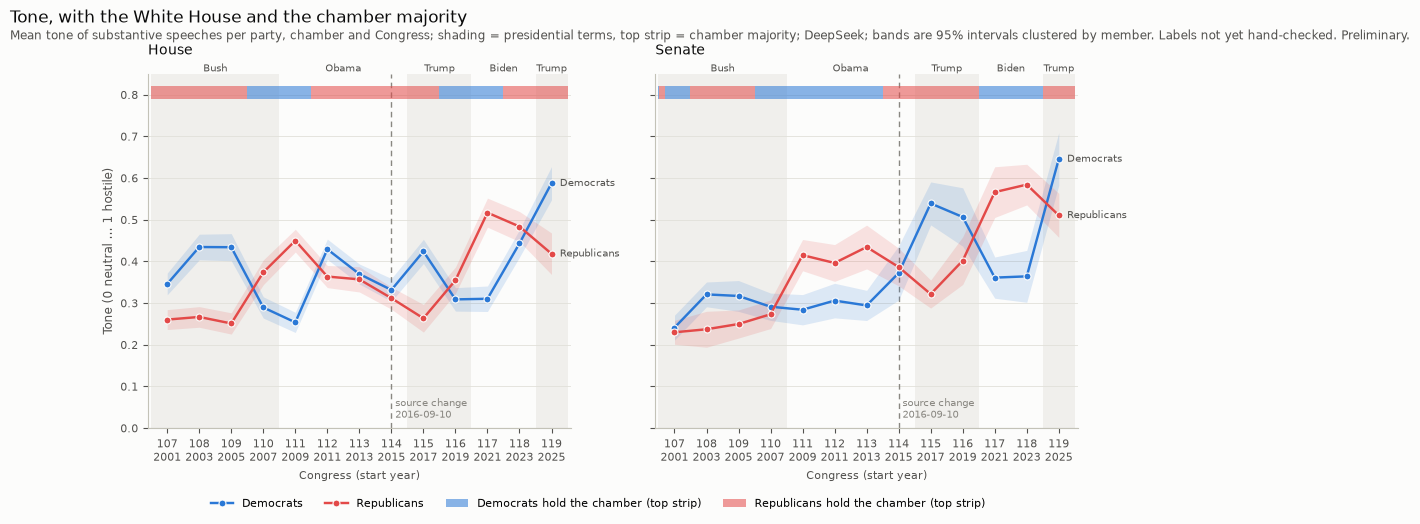

In [7]:
cells = cell_means(df)
fig = plot_positions_with_control(
    cells,
    "Ideology (−1 liberal … +1 conservative)",
    "Where each party stands, with the White House and the chamber majority",
    subtitle="Mean ideology of substantive speeches per party, chamber and Congress; shading = presidential terms, top strip = chamber majority; DeepSeek; bands are 95% intervals clustered by member. Labels not yet hand-checked. Preliminary.",
    ylim=(-0.8, 0.95),
)
save_figure(fig, "deepdive_positions_control")
plt.show()

tone_cells = cell_means(df, value="tone")
fig = plot_positions_with_control(
    tone_cells,
    "Tone (0 neutral … 1 hostile)",
    "Tone, with the White House and the chamber majority",
    subtitle="Mean tone of substantive speeches per party, chamber and Congress; shading = presidential terms, top strip = chamber majority; DeepSeek; bands are 95% intervals clustered by member. Labels not yet hand-checked. Preliminary.",
    ylim=(0, 0.85),
)
save_figure(fig, "deepdive_tone_control")
plt.show()

**The four constellations.** Extremity (ideology toward the party's own side: Republicans as
scored, Democrats sign-flipped, so higher is further out for both) and tone, per party and
chamber, by whether the party holds the White House and whether it holds the speaker's
chamber. Pooled over Congresses, so the long-run trend is mixed in; section 2 takes it out.

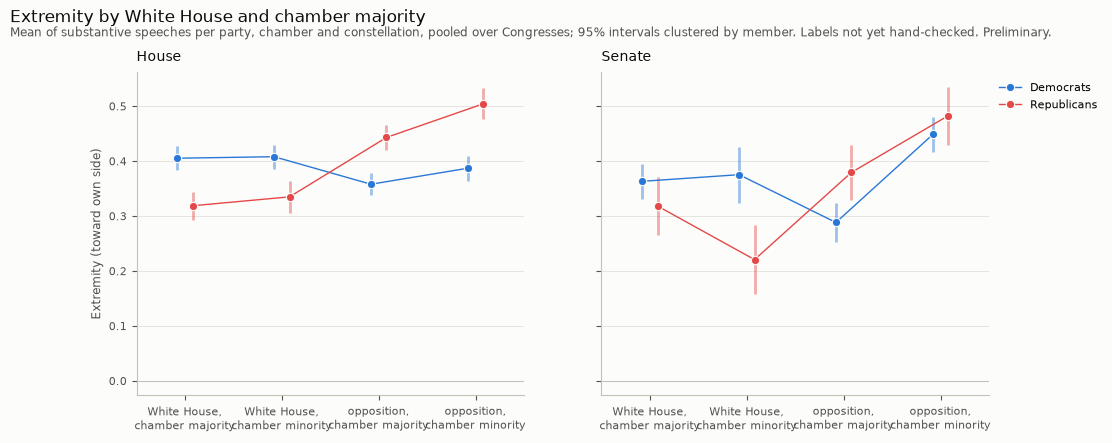

mean_ci                                \
constellation White House, chamber majority White House, chamber minority   
chamber party                                                               
H       D              +0.41 [+0.38, +0.43]          +0.41 [+0.39, +0.43]   
        R              +0.32 [+0.29, +0.34]          +0.33 [+0.31, +0.36]   
S       D              +0.36 [+0.33, +0.39]          +0.38 [+0.32, +0.43]   
        R              +0.32 [+0.27, +0.37]          +0.22 [+0.16, +0.28]   

                                                                         \
constellation opposition, chamber majority opposition, chamber minority   
chamber party                                                             
H       D             +0.36 [+0.34, +0.38]         +0.39 [+0.36, +0.41]   
        R             +0.44 [+0.42, +0.47]         +0.50 [+0.48, +0.53]   
S       D             +0.29 [+0.25, +0.32]         +0.45 [+0.42, +0.48]   
        R             +0.38 [+0.33, +0.43]         +0.48 [+0.43, +0.54]   

                                          n                                \
constellation White House, chamber majority White House, chamber minority   
chamber party                                                               
H       D                              2944                          6229   
        R                              6747                          2803   
S       D                              5574                          1458   
        R                              5727                          2413   

                                                                         \
constellation opposition, chamber majority opposition, chamber minority   
chamber party                                                             
H       D                             2994                         7762   
        R                             5803                         2960   
S       D                             2076                         7684   
        R                             1035                         6912   

                                  n_members                                \
constellation White House, chamber majority White House, chamber minority   
chamber party                                                               
H       D                               358                           352   
        R                               574                           333   
S       D                                98                            46   
        R                               124                            67   

                                                                         
constellation opposition, chamber majority opposition, chamber minority  
chamber party                                                            
H       D                              370                          457  
        R                              453                          333  
S       D                               66                          110  
        R                               56                           90

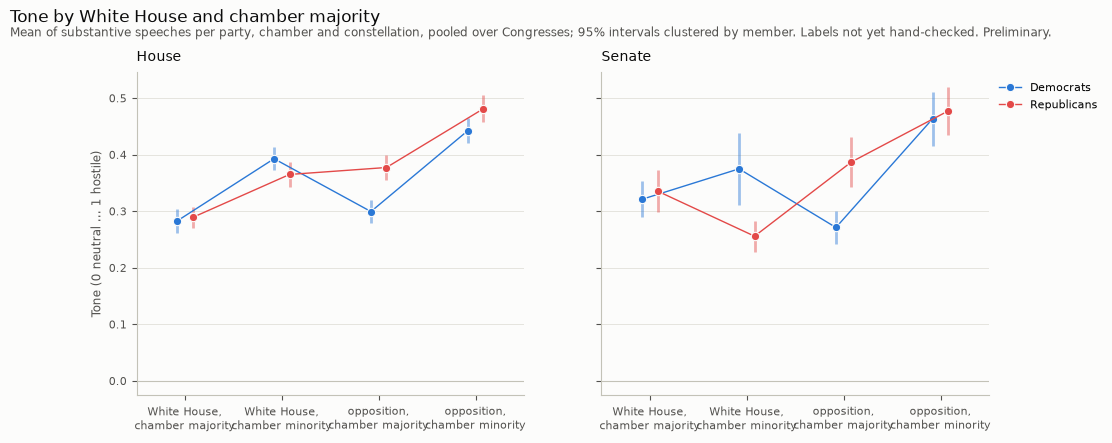

mean_ci                                \
constellation White House, chamber majority White House, chamber minority   
chamber party                                                               
H       D              +0.28 [+0.26, +0.30]          +0.39 [+0.37, +0.41]   
        R              +0.29 [+0.27, +0.31]          +0.36 [+0.34, +0.39]   
S       D              +0.32 [+0.29, +0.35]          +0.37 [+0.31, +0.44]   
        R              +0.34 [+0.30, +0.37]          +0.26 [+0.23, +0.28]   

                                                                         \
constellation opposition, chamber majority opposition, chamber minority   
chamber party                                                             
H       D             +0.30 [+0.28, +0.32]         +0.44 [+0.42, +0.46]   
        R             +0.38 [+0.36, +0.40]         +0.48 [+0.46, +0.50]   
S       D             +0.27 [+0.24, +0.30]         +0.46 [+0.42, +0.51]   
        R             +0.39 [+0.34, +0.43]         +0.48 [+0.43, +0.52]   

                                          n                                \
constellation White House, chamber majority White House, chamber minority   
chamber party                                                               
H       D                              2944                          6229   
        R                              6747                          2803   
S       D                              5574                          1458   
        R                              5727                          2413   

                                                                         \
constellation opposition, chamber majority opposition, chamber minority   
chamber party                                                             
H       D                             2994                         7762   
        R                             5803                         2960   
S       D                             2076                         7684   
        R                             1035                         6912   

                                  n_members                                \
constellation White House, chamber majority White House, chamber minority   
chamber party                                                               
H       D                               358                           352   
        R                               574                           333   
S       D                                98                            46   
        R                               124                            67   

                                                                         
constellation opposition, chamber majority opposition, chamber minority  
chamber party                                                            
H       D                              370                          457  
        R                              453                          333  
S       D                               66                          110  
        R                               56                           90

In [8]:
TICKS = {c: c.replace(", ", ",\n") for c in CONSTELLATIONS}
control_tables = {}
for value, label in (("extremity", "Extremity (toward own side)"), ("tone", "Tone (0 neutral … 1 hostile)")):
    table = control_cells(df, value)
    control_tables[value] = table
    fig = plot_group_means(
        table,
        "constellation",
        f"{label.split(' (')[0]} by White House and chamber majority",
        label,
        subtitle="Mean of substantive speeches per party, chamber and constellation, pooled over Congresses; 95% intervals clustered by member. Labels not yet hand-checked. Preliminary.",
        order=CONSTELLATIONS,
        ticklabels=TICKS,
    )
    save_figure(fig, f"deepdive_control_cells_{value}")
    plt.show()
    display(
        table.assign(mean_ci=with_ci(table)).pivot(
            index=["chamber", "party"], columns="constellation", values=["mean_ci", "n", "n_members"]
        )
    )

**Reading it.** *Not yet run: the run, label, corpus, crosswalk and Voteview files are not in this checkout. Fill in after running, with the numbers from the cells above.*

# Part II — Opposition within members

## 2. Does the same person speak differently once their party loses power?

Per chamber and party, three regressions with member-clustered standard errors
(`analysis.within_cell_ols`), for extremity and for tone:

- **Model A** — notebook 07's (sections 4 and 8): the Congress number and `opposition`
  (out of the White House), with a party-chamber intercept. It must reproduce
  `findings_opposition_effect` and `findings_tone_opposition_effect`; the cell below stops
  if it does not.
- **Model B** — A plus `chamber_minority`.
- **Model C** — B with **member fixed effects**: every variable is taken relative to the
  member's own mean, so a coefficient compares a member with themselves. Only members whose
  status changes while they speak identify it (table below).

In [9]:
COMMITTED = {
    "extremity": METRICS_DIR / f"findings_opposition_effect_{RUN}.csv",
    "tone": METRICS_DIR / f"findings_tone_opposition_effect_{RUN}.csv",
}
models = {}
for value, path in COMMITTED.items():
    models[value] = opposition_models(df, value)
    model_a = models[value][models[value]["model"] == "A"]
    check_reproduces(model_a[["chamber", "party", "term", "coef", "se"]], pd.read_csv(path))
    print(f"{value}: model A reproduces {path.name}")

extremity: model A reproduces findings_opposition_effect_20261018T122536Z.csv
tone: model A reproduces findings_tone_opposition_effect_20261018T122536Z.csv


In [10]:
for value, fit in models.items():
    print(f"{value}: coefficient [95% interval], member-clustered")
    display(model_table(fit))

extremity: coefficient [95% interval], member-clustered


term                        opposition                           \
model                                A                        B   
chamber party                                                     
H       D      +0.004 [-0.012, +0.021]  +0.004 [-0.013, +0.021]   
        R      +0.110 [+0.087, +0.133]  +0.109 [+0.087, +0.132]   
S       D      +0.093 [+0.069, +0.117]  +0.070 [+0.039, +0.101]   
        R      +0.130 [+0.100, +0.159]  +0.107 [+0.069, +0.145]   

term                  chamber_minority               opposition  \
model                                B                        C   
chamber party                                                     
H       D      +0.028 [+0.012, +0.044]  +0.019 [+0.004, +0.033]   
        R      +0.031 [+0.010, +0.053]  +0.089 [+0.070, +0.108]   
S       D      +0.035 [+0.011, +0.060]  +0.069 [+0.040, +0.099]   
        R      +0.035 [+0.007, +0.063]  +0.096 [+0.068, +0.124]   

term                  chamber_minority  
model                                C  
chamber party                           
H       D      +0.017 [+0.003, +0.032]  
        R      +0.003 [-0.015, +0.021]  
S       D      +0.031 [+0.010, +0.051]  
        R      +0.015 [-0.013, +0.042]

tone: coefficient [95% interval], member-clustered


term                        opposition                           \
model                                A                        B   
chamber party                                                     
H       D      +0.065 [+0.048, +0.082]  +0.063 [+0.047, +0.080]   
        R      +0.076 [+0.058, +0.093]  +0.074 [+0.056, +0.091]   
S       D      +0.141 [+0.106, +0.176]  +0.100 [+0.057, +0.142]   
        R      +0.099 [+0.078, +0.120]  +0.067 [+0.042, +0.091]   

term                  chamber_minority               opposition  \
model                                B                        C   
chamber party                                                     
H       D      +0.136 [+0.119, +0.152]  +0.062 [+0.046, +0.078]   
        R      +0.084 [+0.068, +0.100]  +0.070 [+0.056, +0.084]   
S       D      +0.065 [+0.042, +0.088]  +0.103 [+0.070, +0.135]   
        R      +0.049 [+0.025, +0.072]  +0.070 [+0.053, +0.087]   

term                  chamber_minority  
model                                C  
chamber party                           
H       D      +0.124 [+0.108, +0.140]  
        R      +0.073 [+0.058, +0.089]  
S       D      +0.054 [+0.036, +0.072]  
        R      +0.031 [+0.007, +0.054]

In [11]:
print("Members who identify model C (their status changes while they speak):")
identifying = identifying_members(df)
identifying

Members who identify model C (their status changes while they speak):


,chamber,party,term,n_members,n_identifying,n_speeches_identifying
0,H,D,opposition,580,378,18013
1,H,D,chamber_minority,580,357,18011
2,H,R,opposition,695,402,15252
3,H,R,chamber_minority,695,385,15253
4,S,D,opposition,123,86,15790
5,S,D,chamber_minority,123,102,16486
6,S,R,opposition,132,85,13870
7,S,R,chamber_minority,132,114,15805


**Robustness of model C.** Without the party switchers (`party_switch`, D23), and without
Specter's speeches the Stanford data code as Democratic before his switch on 28 April 2009
(O13).

In [12]:
miscoded = specter_miscoded(df)
print(f"Specter's speeches coded D before 2009-04-28: {miscoded.sum()} (O13 expects about 90 after A3)")
robustness = []
for sample, frame in robustness_samples(df).items():
    for value in COMMITTED:
        fit = opposition_models(frame, value)
        robustness.append(fit[fit["model"] == "C"].assign(sample=sample, n_speeches=len(frame)))
robustness = pd.concat(robustness, ignore_index=True)
robustness.assign(coef_ci=with_ci(robustness, "coef", 3)).pivot(
    index=["value", "chamber", "party", "term"], columns="sample", values="coef_ci"
).loc[(slice(None), slice(None), slice(None), ["opposition", "chamber_minority"]), :]

Specter's speeches coded D before 2009-04-28: 103 (O13 expects about 90 after A3)


sample                                               all speeches  \
value     chamber party term                                        
extremity H       D     opposition        +0.019 [+0.004, +0.033]   
                  R     opposition        +0.089 [+0.070, +0.108]   
          S       D     opposition        +0.069 [+0.040, +0.099]   
                  R     opposition        +0.096 [+0.068, +0.124]   
tone      H       D     opposition        +0.062 [+0.046, +0.078]   
                  R     opposition        +0.070 [+0.056, +0.084]   
          S       D     opposition        +0.103 [+0.070, +0.135]   
                  R     opposition        +0.070 [+0.053, +0.087]   
extremity H       D     chamber_minority  +0.017 [+0.003, +0.032]   
                  R     chamber_minority  +0.003 [-0.015, +0.021]   
          S       D     chamber_minority  +0.031 [+0.010, +0.051]   
                  R     chamber_minority  +0.015 [-0.013, +0.042]   
tone      H       D     chamber_minority  +0.124 [+0.108, +0.140]   
                  R     chamber_minority  +0.073 [+0.058, +0.089]   
          S       D     chamber_minority  +0.054 [+0.036, +0.072]   
                  R     chamber_minority  +0.031 [+0.007, +0.054]   

sample                                   without Specter 2005–2009  \
value     chamber party term                                         
extremity H       D     opposition         +0.019 [+0.004, +0.033]   
                  R     opposition         +0.089 [+0.070, +0.108]   
          S       D     opposition         +0.069 [+0.040, +0.099]   
                  R     opposition         +0.096 [+0.068, +0.124]   
tone      H       D     opposition         +0.062 [+0.046, +0.078]   
                  R     opposition         +0.070 [+0.056, +0.084]   
          S       D     opposition         +0.102 [+0.070, +0.134]   
                  R     opposition         +0.070 [+0.053, +0.087]   
extremity H       D     chamber_minority   +0.017 [+0.003, +0.032]   
                  R     chamber_minority   +0.003 [-0.015, +0.021]   
          S       D     chamber_minority   +0.031 [+0.010, +0.052]   
                  R     chamber_minority   +0.015 [-0.013, +0.042]   
tone      H       D     chamber_minority   +0.124 [+0.108, +0.140]   
                  R     chamber_minority   +0.073 [+0.058, +0.089]   
          S       D     chamber_minority   +0.055 [+0.038, +0.073]   
                  R     chamber_minority   +0.031 [+0.007, +0.054]   

sample                                    without party switchers  
value     chamber party term                                       
extremity H       D     opposition        +0.019 [+0.004, +0.033]  
                  R     opposition        +0.089 [+0.070, +0.108]  
          S       D     opposition        +0.069 [+0.040, +0.099]  
                  R     opposition        +0.096 [+0.068, +0.124]  
tone      H       D     opposition        +0.062 [+0.046, +0.078]  
                  R     opposition        +0.070 [+0.056, +0.085]  
          S       D     opposition        +0.103 [+0.070, +0.135]  
                  R     opposition        +0.070 [+0.053, +0.087]  
extremity H       D     chamber_minority  +0.017 [+0.003, +0.032]  
                  R     chamber_minority  +0.004 [-0.015, +0.022]  
          S       D     chamber_minority  +0.030 [+0.010, +0.051]  
                  R     chamber_minority  +0.015 [-0.013, +0.042]  
tone      H       D     chamber_minority  +0.124 [+0.108, +0.140]  
                  R     chamber_minority  +0.073 [+0.058, +0.089]  
          S       D     chamber_minority  +0.054 [+0.037, +0.072]  
                  R     chamber_minority  +0.031 [+0.007, +0.054]

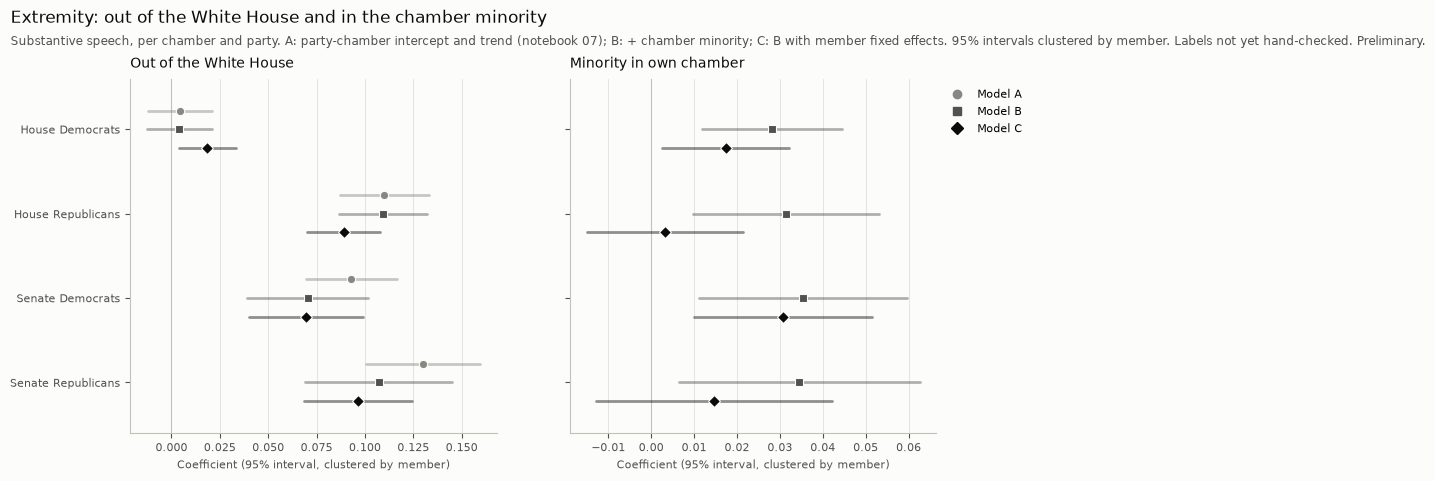

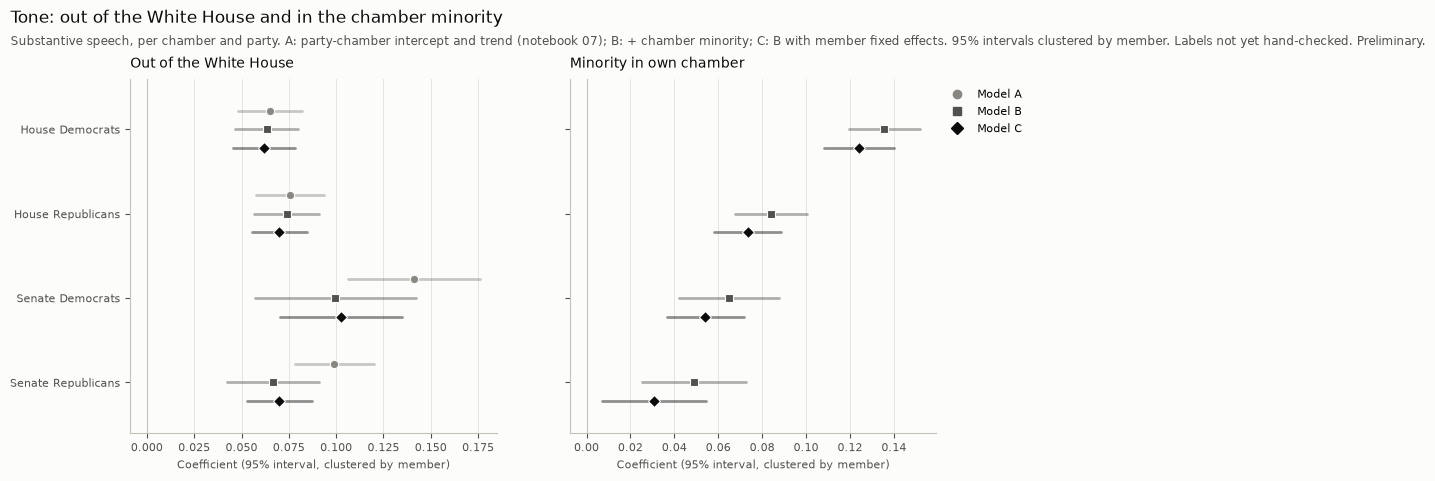

In [13]:
for value, label in (("extremity", "Extremity"), ("tone", "Tone")):
    fig = plot_opposition_models(
        models[value],
        f"{label}: out of the White House and in the chamber minority",
        subtitle="Substantive speech, per chamber and party. A: party-chamber intercept and trend (notebook 07); B: + chamber minority; C: B with member fixed effects. 95% intervals clustered by member. Labels not yet hand-checked. Preliminary.",
    )
    save_figure(fig, f"deepdive_opposition_models_{value}")
    plt.show()

**Reading it.** *Not yet run: the run, label, corpus, crosswalk and Voteview files are not in this checkout. Fill in after running, with the numbers from the cells above.*

# Part III — Topics

## 3. The party gap per topic block, in one model

Policy debates only (labels not yet hand-checked, L4). Per chamber, one saturated regression
of ideology on party × topic block × Congress, **Congress as a category**, member-clustered:
each coefficient is a cell mean, so the gaps equal those of `overview_gap_by_topic_block`,
and the joint covariance lets blocks and Congresses be tested against each other. All five
blocks; the 11 single topics are in `findings_gap_trends_by_topic` (07, section 6).

First the cell sizes: a party × block × Congress × chamber cell with fewer than
`TOPIC_MIN_CELL` (30) speeches is listed, and the model below waits until it has been
looked at.

In [14]:
sizes = topic_cell_sizes(policy)
small = sizes[sizes["below_min"]]
print(f"{len(small)} of {len(sizes)} cells under {TOPIC_MIN_CELL} policy debates:")
small

0 of 260 cells under 30 policy debates:


,congress_number,chamber,topic_block,party,n,n_members,below_min


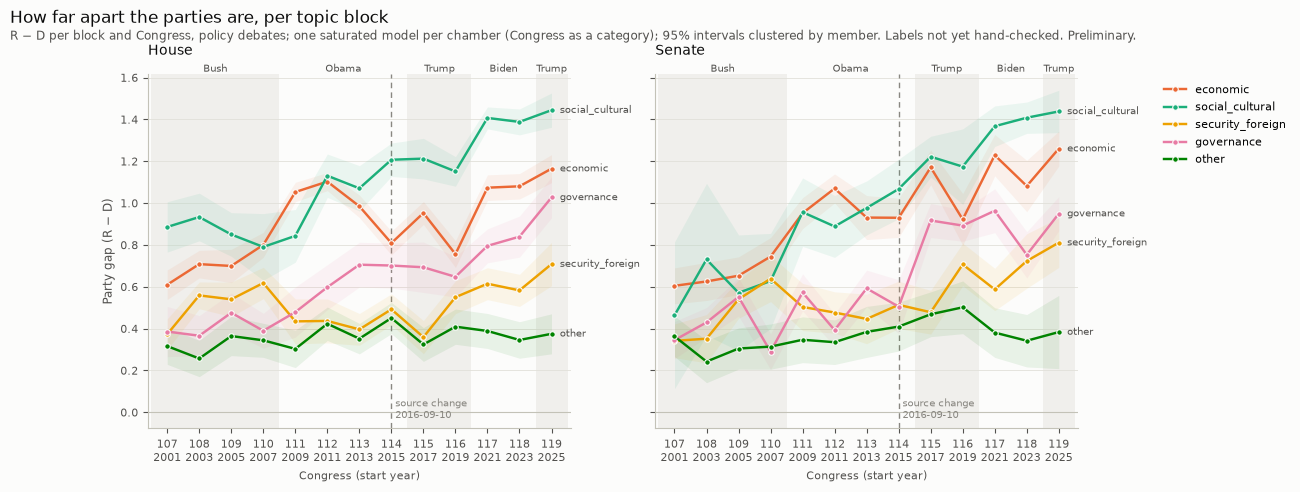

Change in the gap, 107th → 118th, per block; last row per chamber: do the blocks' changes differ?


,chamber,topic_block,span,change,se,ci_low,ci_high,p,chi2,df
0,H,economic,107-118,0.470,0.048,0.377,0.564,4.171e-23,NaN,NaN
1,H,social_cultural,107-118,0.502,0.071,0.362,0.642,2.013e-12,NaN,NaN
2,H,security_foreign,107-118,0.210,0.052,0.109,0.311,4.869e-05,NaN,NaN
3,H,governance,107-118,0.454,0.077,0.303,0.604,3.327e-09,NaN,NaN
4,H,other,107-118,0.029,0.062,-0.092,0.151,6.361e-01,NaN,NaN
5,H,all (joint),107-118,NaN,NaN,NaN,NaN,2.354e-10,50.890,4.0
6,S,economic,107-118,0.477,0.074,0.332,0.622,1.055e-10,NaN,NaN
7,S,social_cultural,107-118,0.945,0.183,0.586,1.303,2.414e-07,NaN,NaN
8,S,security_foreign,107-118,0.382,0.080,0.224,0.539,2.067e-06,NaN,NaN
9,S,governance,107-118,0.408,0.061,0.287,0.528,3.292e-11,NaN,NaN


In [15]:
# Set to True once the small cells above have been reviewed (and say how in the reading).
ACCEPT_SMALL_CELLS = False
if len(small) and not ACCEPT_SMALL_CELLS:
    raise RuntimeError(f"{len(small)} cells under {TOPIC_MIN_CELL} speeches: review them, then set ACCEPT_SMALL_CELLS")

fits = {chamber: fit_topic_model(policy, chamber) for chamber in ("H", "S")}
topic_gap_table = pd.concat([topic_gaps(fit, chamber) for chamber, fit in fits.items()], ignore_index=True)
topic_tests = pd.concat(
    [topic_gap_tests(fit, chamber, TOPIC_TEST_CONGRESSES) for chamber, fit in fits.items()],
    ignore_index=True,
)
fig = plot_gap_by_group(
    topic_gap_table,
    "topic_block",
    "How far apart the parties are, per topic block",
    subtitle="R − D per block and Congress, policy debates; one saturated model per chamber (Congress as a category); 95% intervals clustered by member. Labels not yet hand-checked. Preliminary.",
    order=tuple(TOPIC_BLOCKS),
)
save_figure(fig, "deepdive_topic_gaps")
plt.show()

base, compare = TOPIC_TEST_CONGRESSES
print(f"Change in the gap, {base}th → {compare}th, per block; last row per chamber: do the blocks' changes differ?")
topic_tests

**Reading it.** *Not yet run: the run, label, corpus, crosswalk and Voteview files are not in this checkout. Fill in after running, with the numbers from the cells above.*

## 4. Agenda against positions

The gap among policy debates is, per chamber and Congress,
G = Σ_k s^R_k μ^R_k − Σ_k s^D_k μ^D_k, with each party's own block shares s and block means
μ (Republicans and Democrats debate different things). Shares are sample shares within each
party × chamber × Congress cell; every cell is drawn at random with the same quota (S11).
The change in G splits exactly into

- **positions** — Σ s̄ Δμ: the parties moving within blocks;
- **agenda** — Σ μ̄ Δs: the debate shifting between blocks;

the two-factor Shapley values, with no residual. Per block, the agenda part is measured
against the party's own mean, so a block adds to the gap when it gains share and sits
further out than the party's average. Two comparisons: 107th → 118th, and the
107th–114th against the 115th–119th. For a period, each block's share and mean are first
averaged over its Congresses (each weighted equally) and G is computed from those averages:
the decomposition is exact for that G, which can differ slightly (in the third decimal) from
the mean of the per-Congress gaps. For the single Congresses G is exactly the policy-debate
gap, which the cell below checks.
Intervals: bootstrap over members (`DEEP_DIVE_BOOTSTRAP` draws, seed 42), per chamber.

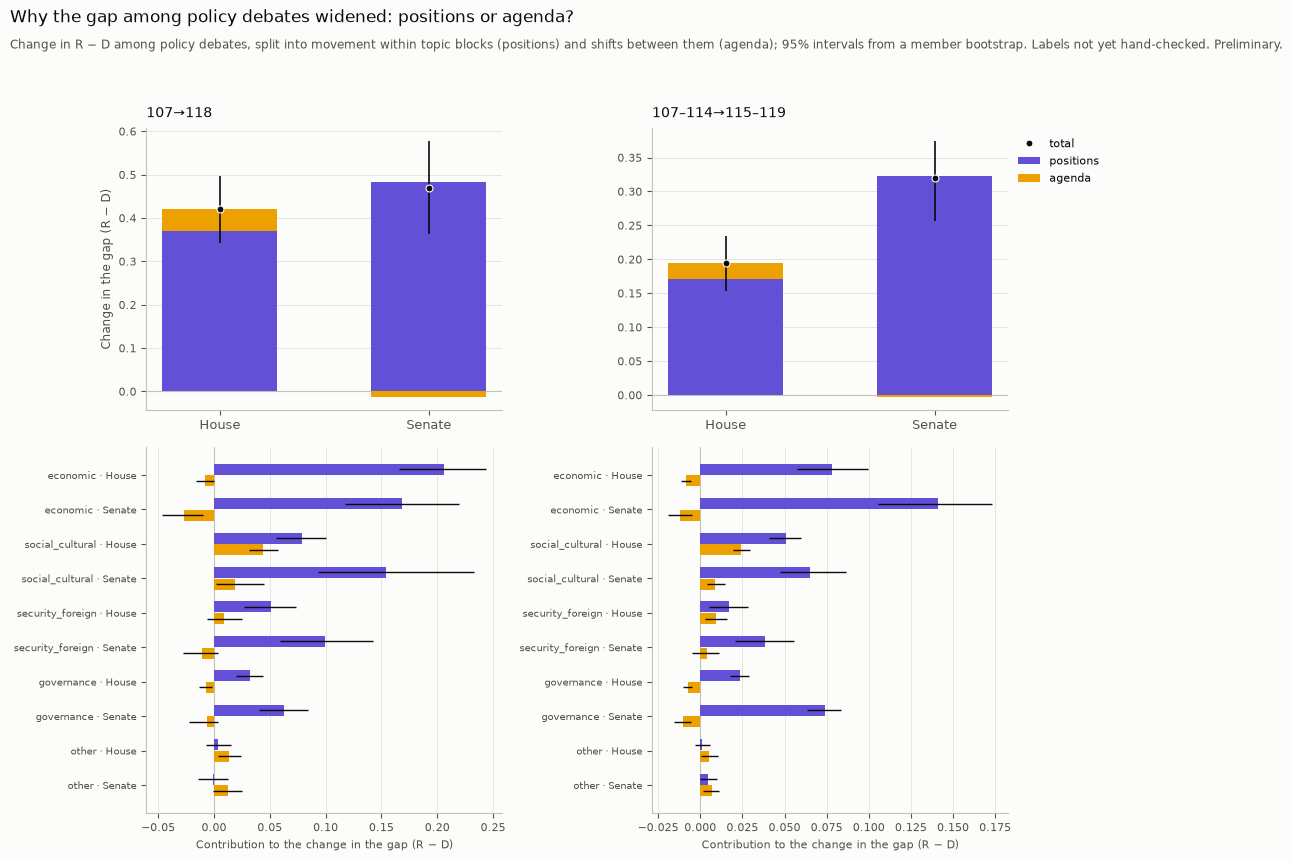

component                              agenda             positions  \
comparison      chamber                                               
107–114→115–119 H        +0.02 [+0.01, +0.03]  +0.17 [+0.13, +0.21]   
                S        -0.00 [-0.02, +0.01]  +0.32 [+0.26, +0.38]   
107→118         H        +0.05 [+0.02, +0.08]  +0.37 [+0.31, +0.43]   
                S        -0.01 [-0.05, +0.03]  +0.48 [+0.37, +0.59]   

component                               total  
comparison      chamber                        
107–114→115–119 H        +0.19 [+0.15, +0.23]  
                S        +0.32 [+0.26, +0.37]  
107→118         H        +0.42 [+0.34, +0.50]  
                S        +0.47 [+0.36, +0.58]

In [16]:
decomposition = bootstrap_gap_decomposition(policy, DECOMPOSITION_COMPARISONS, n_draws=DEEP_DIVE_BOOTSTRAP)
fig = plot_gap_decomposition(
    decomposition,
    "Why the gap among policy debates widened: positions or agenda?",
    subtitle="Change in R − D among policy debates, split into movement within topic blocks (positions) and shifts between them (agenda); 95% intervals from a member bootstrap. Labels not yet hand-checked. Preliminary.",
    comparisons=tuple(DECOMPOSITION_COMPARISONS),
    blocks=tuple(TOPIC_BLOCKS),
)
save_figure(fig, "deepdive_gap_decomposition")
plt.show()

# Check: for single Congresses, G is the policy-debate gap of the cell means.
policy_gap = party_gap(cell_means(policy)).set_index(["congress_number", "chamber"])["gap"]
totals = decomposition[(decomposition["component"] == "total") & (decomposition["comparison"] == "107→118")]
for _, row in totals.iterrows():
    assert abs(row["gap_base"] - policy_gap[(107, row["chamber"])]) < 1e-12
    assert abs(row["gap_compare"] - policy_gap[(118, row["chamber"])]) < 1e-12

overall = decomposition[decomposition["topic_block"] == "all"]
overall.assign(value_ci=with_ci(overall, "value")).pivot(
    index=["comparison", "chamber"], columns="component", values="value_ci"
)

In [17]:
blocks = decomposition[decomposition["topic_block"] != "all"]
blocks.assign(value_ci=with_ci(blocks, "value")).pivot(
    index=["comparison", "chamber", "topic_block"], columns="component", values="value_ci"
)

component                                               agenda  \
comparison      chamber topic_block                              
107–114→115–119 H       economic          -0.01 [-0.01, -0.01]   
                        governance        -0.01 [-0.01, -0.01]   
                        other             +0.01 [+0.00, +0.01]   
                        security_foreign  +0.01 [+0.00, +0.02]   
                        social_cultural   +0.02 [+0.02, +0.03]   
                S       economic          -0.01 [-0.02, -0.00]   
                        governance        -0.01 [-0.02, -0.01]   
                        other             +0.01 [+0.00, +0.01]   
                        security_foreign  +0.00 [-0.01, +0.01]   
                        social_cultural   +0.01 [+0.00, +0.01]   
107→118         H       economic          -0.01 [-0.02, -0.00]   
                        governance        -0.01 [-0.01, -0.00]   
                        other             +0.01 [+0.00, +0.02]   
                        security_foreign  +0.01 [-0.01, +0.02]   
                        social_cultural   +0.04 [+0.03, +0.06]   
                S       economic          -0.03 [-0.05, -0.01]   
                        governance        -0.01 [-0.02, +0.00]   
                        other             +0.01 [-0.00, +0.02]   
                        security_foreign  -0.01 [-0.03, +0.00]   
                        social_cultural   +0.02 [+0.00, +0.04]   

component                                            positions  
comparison      chamber topic_block                             
107–114→115–119 H       economic          +0.08 [+0.06, +0.10]  
                        governance        +0.02 [+0.02, +0.03]  
                        other             +0.00 [-0.00, +0.01]  
                        security_foreign  +0.02 [+0.01, +0.03]  
                        social_cultural   +0.05 [+0.04, +0.06]  
                S       economic          +0.14 [+0.11, +0.17]  
                        governance        +0.07 [+0.06, +0.08]  
                        other             +0.00 [-0.00, +0.01]  
                        security_foreign  +0.04 [+0.02, +0.06]  
                        social_cultural   +0.06 [+0.05, +0.09]  
107→118         H       economic          +0.21 [+0.17, +0.24]  
                        governance        +0.03 [+0.02, +0.04]  
                        other             +0.00 [-0.01, +0.01]  
                        security_foreign  +0.05 [+0.03, +0.07]  
                        social_cultural   +0.08 [+0.06, +0.10]  
                S       economic          +0.17 [+0.12, +0.22]  
                        governance        +0.06 [+0.04, +0.08]  
                        other             -0.00 [-0.01, +0.01]  
                        security_foreign  +0.10 [+0.06, +0.14]  
                        social_cultural   +0.15 [+0.09, +0.23]

**Reading it.** *Not yet run: the run, label, corpus, crosswalk and Voteview files are not in this checkout. Fill in after running, with the numbers from the cells above.*

# Part IV — Who moved the parties

## 5. Replacement against adaptation

Per chamber and party, each step from one Congress to the next splits the change in the
party's mean ideology exactly into

ΔM = (m_s′ − m_s) + w_n (m_n − m_s′) − w_x (m_x − m_s) + [unmatched]

- **adaptation** — the stayers' own change (s: members in the chamber in both Congresses);
- **entry** — the entrants (n) against the stayers, weighted by their share of speeches;
- **exit** — the leavers (x) against the stayers;
- **unmatched** — the few speeches without an ICPSR, kept rather than dropped.

**Replacement** = entry + exit. Means are speech-weighted, since the run draws speeches,
not members. Who stays, enters or leaves follows actual membership (Voteview), not presence
in the sample; a move between chambers counts as exit from one and entry into the other,
and a party switcher's new ICPSR as an entry. Summed over 2001–2016 and 2001–2025, with a
member bootstrap; a robustness check without party switchers and Specter follows.

**Validation caveat.** The replacement part rests on differences between members within a
Congress, which the scores order as votes do (within-cell r = 0.54, A5); the adaptation part
rests on movement over time, which the validation supports only weakly (r = 0.14 for
changes between Congresses, A5).

In [18]:
membership = chamber_membership()
steps = turnover_decomposition(df, membership)
assert ((steps[["adaptation", "entry", "exit", "unmatched"]].sum(axis=1) - steps["delta"]).abs() < 1e-12).all()

without = stayers_without_speeches(df, membership)
print("Stayers with no sampled speech in one of the two Congresses (sum over steps):")
without.groupby(["chamber", "party"])[["n_stayers", "no_speech_before", "no_speech_after"]].sum()

Stayers with no sampled speech in one of the two Congresses (sum over steps):


n_stayers  no_speech_before  no_speech_after
chamber party                                              
H       D           2209               151              196
        R           2228               164              216
S       D            533                 7                5
        R            528                 3                4

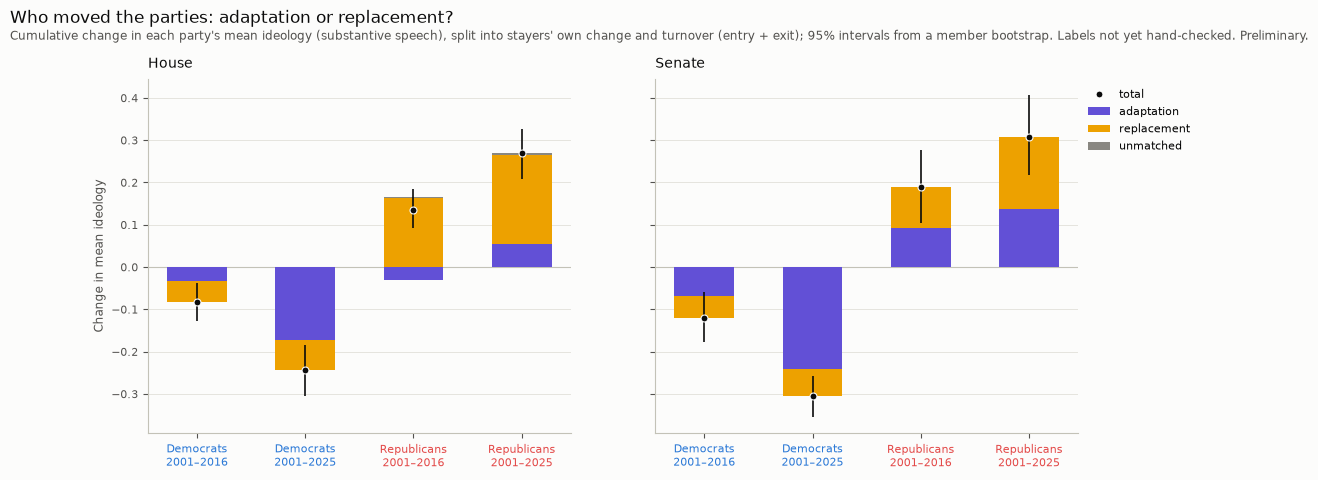

component                                             delta  \
window                  chamber party                         
2001–2016 (107th–114th) H       D      -0.08 [-0.13, -0.04]   
                                R      +0.14 [+0.09, +0.18]   
                        S       D      -0.12 [-0.18, -0.06]   
                                R      +0.19 [+0.11, +0.28]   
2001–2025 (107th–119th) H       D      -0.24 [-0.31, -0.18]   
                                R      +0.27 [+0.21, +0.33]   
                        S       D      -0.30 [-0.35, -0.26]   
                                R      +0.31 [+0.22, +0.41]   

component                                        adaptation  \
window                  chamber party                         
2001–2016 (107th–114th) H       D      -0.03 [-0.08, +0.02]   
                                R      -0.03 [-0.08, +0.02]   
                        S       D      -0.07 [-0.13, +0.01]   
                                R      +0.09 [+0.00, +0.17]   
2001–2025 (107th–119th) H       D      -0.17 [-0.24, -0.10]   
                                R      +0.05 [-0.03, +0.13]   
                        S       D      -0.24 [-0.31, -0.17]   
                                R      +0.14 [+0.02, +0.22]   

component                                       replacement  \
window                  chamber party                         
2001–2016 (107th–114th) H       D      -0.05 [-0.09, -0.01]   
                                R      +0.16 [+0.12, +0.21]   
                        S       D      -0.05 [-0.12, -0.00]   
                                R      +0.10 [+0.04, +0.17]   
2001–2025 (107th–119th) H       D      -0.07 [-0.13, -0.02]   
                                R      +0.21 [+0.15, +0.27]   
                        S       D      -0.06 [-0.14, -0.00]   
                                R      +0.17 [+0.10, +0.27]   

component                                             entry  \
window                  chamber party                         
2001–2016 (107th–114th) H       D      +0.00 [-0.03, +0.03]   
                                R      +0.09 [+0.05, +0.12]   
                        S       D      -0.03 [-0.07, -0.00]   
                                R      +0.05 [+0.01, +0.10]   
2001–2025 (107th–119th) H       D      -0.00 [-0.05, +0.04]   
                                R      +0.08 [+0.03, +0.13]   
                        S       D      -0.04 [-0.07, -0.00]   
                                R      +0.08 [+0.03, +0.16]   

component                                              exit  \
window                  chamber party                         
2001–2016 (107th–114th) H       D      -0.05 [-0.08, -0.03]   
                                R      +0.08 [+0.04, +0.11]   
                        S       D      -0.02 [-0.07, +0.02]   
                                R      +0.04 [-0.01, +0.10]   
2001–2025 (107th–119th) H       D      -0.07 [-0.10, -0.03]   
                                R      +0.13 [+0.08, +0.18]   
                        S       D      -0.03 [-0.08, +0.02]   
                                R      +0.09 [+0.01, +0.17]   

component                                         unmatched  
window                  chamber party                        
2001–2016 (107th–114th) H       D      -0.00 [-0.00, +0.00]  
                                R      +0.00 [+0.00, +0.01]  
                        S       D      +0.00 [+0.00, +0.00]  
                                R      +0.00 [+0.00, +0.00]  
2001–2025 (107th–119th) H       D      -0.00 [-0.00, +0.00]  
                                R      +0.00 [+0.00, +0.01]  
                        S       D      +0.00 [+0.00, +0.00]  
                                R      +0.00 [+0.00, +0.00]

In [19]:
turnover = bootstrap_turnover(df, membership, windows=TURNOVER_WINDOWS, n_draws=DEEP_DIVE_BOOTSTRAP)
fig = plot_turnover(
    turnover,
    "Who moved the parties: adaptation or replacement?",
    subtitle="Cumulative change in each party's mean ideology (substantive speech), split into stayers' own change and turnover (entry + exit); 95% intervals from a member bootstrap. Labels not yet hand-checked. Preliminary.",
    windows=tuple(TURNOVER_WINDOWS),
)
save_figure(fig, "deepdive_turnover")
plt.show()

# Check: each party's cumulative move is the change in its mean from section 1.
means = cells.set_index(["chamber", "party", "congress_number"])["mean"]
moves = turnover[turnover["component"] == "delta"]
for _, row in moves.iterrows():
    first, last = TURNOVER_WINDOWS[row["window"]]
    expected = means[(row["chamber"], row["party"], last)] - means[(row["chamber"], row["party"], first)]
    assert abs(row["value"] - expected) < 1e-12

turnover.assign(value_ci=with_ci(turnover, "value")).pivot(
    index=["window", "chamber", "party"], columns="component", values="value_ci"
)[["delta", "adaptation", "replacement", "entry", "exit", "unmatched"]]

**Robustness.** A member the data relabel without a new ICPSR stays a "stayer" across the
relabelling, so their move counts as adaptation of both parties instead of exit and entry:
Specter, coded D from the 109th Congress on the Stanford side (O13), and the other Stanford
switchers (D23). The same decomposition without the party switchers and without Specter's
miscoded speeches; point estimates. The main decomposition above keeps every speech, to match
notebook 07.

In [20]:
turnover_robust = turnover_robustness(df, membership, windows=TURNOVER_WINDOWS)
turnover_robust[turnover_robust["component"].isin(["delta", "adaptation", "replacement"])].pivot(
    index=["window", "chamber", "party", "component"], columns="sample", values="value"
)

sample                                             all speeches  \
window                  chamber party component                   
2001–2016 (107th–114th) H       D     adaptation         -0.032   
                                      delta              -0.083   
                                      replacement        -0.051   
                                R     adaptation         -0.031   
                                      delta               0.135   
                                      replacement         0.162   
                        S       D     adaptation         -0.068   
                                      delta              -0.121   
                                      replacement        -0.052   
                                R     adaptation          0.093   
                                      delta               0.188   
                                      replacement         0.096   
2001–2025 (107th–119th) H       D     adaptation         -0.172   
                                      delta              -0.243   
                                      replacement        -0.071   
                                R     adaptation          0.054   
                                      delta               0.269   
                                      replacement         0.212   
                        S       D     adaptation         -0.241   
                                      delta              -0.304   
                                      replacement        -0.063   
                                R     adaptation          0.137   
                                      delta               0.308   
                                      replacement         0.171   

sample                                             without Specter 2005–2009  \
window                  chamber party component                                
2001–2016 (107th–114th) H       D     adaptation                      -0.032   
                                      delta                           -0.083   
                                      replacement                     -0.051   
                                R     adaptation                      -0.031   
                                      delta                            0.135   
                                      replacement                      0.162   
                        S       D     adaptation                      -0.069   
                                      delta                           -0.121   
                                      replacement                     -0.052   
                                R     adaptation                       0.093   
                                      delta                            0.188   
                                      replacement                      0.096   
2001–2025 (107th–119th) H       D     adaptation                      -0.172   
                                      delta                           -0.243   
                                      replacement                     -0.071   
                                R     adaptation                       0.054   
                                      delta                            0.269   
                                      replacement                      0.212   
                        S       D     adaptation                      -0.242   
                                      delta                           -0.304   
                                      replacement                     -0.062   
                                R     adaptation                       0.137   
                                      delta                            0.308   
                                      replacement                      0.171   

sample                                             without party switchers  
window                  chamber party component                             
2001–2016 (107th–114th

**Reading it.** *Not yet run: the run, label, corpus, crosswalk and Voteview files are not in this checkout. Fill in after running, with the numbers from the cells above.*

## Saving the tables

The numbers behind the figures, to `results/metrics/deepdive_*` (committed). This cell stays
last.

In [21]:
tables = {
    "chamber_control": control,
    "control_cells_extremity": control_tables["extremity"],
    "control_cells_tone": control_tables["tone"],
    "opposition_models": pd.concat(models.values(), ignore_index=True),
    "opposition_identifying": identifying,
    "opposition_robustness": robustness,
    "topic_cell_sizes": sizes,
    "topic_gaps": topic_gap_table,
    "topic_gap_tests": topic_tests,
    "gap_decomposition": decomposition,
    "turnover_steps": steps,
    "turnover_stayers_without_speeches": without,
    "turnover_cumulative": turnover,
    "turnover_robustness": turnover_robust,
}
for name, table in tables.items():
    path = METRICS_DIR / f"deepdive_{name}_{RUN}.csv"
    table.to_csv(path, index=False)
    print(path.relative_to(ROOT))

results/metrics/deepdive_chamber_control_20261018T122536Z.csv
results/metrics/deepdive_control_cells_extremity_20261018T122536Z.csv
results/metrics/deepdive_control_cells_tone_20261018T122536Z.csv
results/metrics/deepdive_opposition_models_20261018T122536Z.csv
results/metrics/deepdive_opposition_identifying_20261018T122536Z.csv
results/metrics/deepdive_opposition_robustness_20261018T122536Z.csv
results/metrics/deepdive_topic_cell_sizes_20261018T122536Z.csv
results/metrics/deepdive_topic_gaps_20261018T122536Z.csv
results/metrics/deepdive_topic_gap_tests_20261018T122536Z.csv
results/metrics/deepdive_gap_decomposition_20261018T122536Z.csv
results/metrics/deepdive_turnover_steps_20261018T122536Z.csv
results/metrics/deepdive_turnover_stayers_without_speeches_20261018T122536Z.csv
results/metrics/deepdive_turnover_cumulative_20261018T122536Z.csv
results/metrics/deepdive_turnover_robustness_20261018T122536Z.csv
